# 08 — Binance and the reference feed: compare like with like

**Question:** Why can two BTC price feeds disagree?

**By the end:** align observations without future information, compare freshness,
separate instantaneous trades from a TWAP, and interpret lead–lag diagnostics
without claiming a latency advantage. **Time:** 30–40 minutes.

**Inputs:** Binance trades, reference observations and operational events.
The recorded reference channel is a BTC/USD 60-second TWAP. Binance trades are
BTC/USDT. Aggregation and quote currency are both important differences.

In [1]:
import sys
from pathlib import Path

for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / "src/tyrex_pm").exists():
        sys.path.insert(0, str(directory / "src"))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from tyrex_pm.research.tuto_btc5m.advanced import (
    reference_grid,
)
from tyrex_pm.research.tuto_btc5m.analysis import (
    btc_grid,
    finish_plot,
    plot_style,
)
from tyrex_pm.research.tuto_btc5m.data import Sample

SAMPLE_PATH = None  # Or Path("/absolute/path/to/your/prepared_sample")
sample = Sample.open(SAMPLE_PATH)
plot_style()
pd.set_option("display.max_columns", 12)
display(pd.Series(sample.describe(), name="Pinned input"))

collection                             2dd3d0d125dc4a9fb5e50daf3f9bfd3e
market                polymarket:condition:0x540c56b66edcf6f1273c7d7...
start_utc                                     2026-10-01 15:45:00+00:00
end_utc                                       2026-10-01 15:50:00+00:00
manifest_sha256       f5a2aa939c7d60a1f48d1f6df5c0110a61dc11a7794458...
integrity_scope       selected_normalized_parts_and_sample_only_not_...
semantic_readiness                                          UNSUPPORTED
Name: Pinned input, dtype: object

## 1. Inspect measurement semantics before merging

The feed channel name alone is not enough: inspect the observed fields, timestamps
and carried-forward flags. A TWAP summarizes an interval. It is not interchangeable
with the latest trade, nor does it automatically define the contract's threshold.
The [provider overview](https://docs.polymarket.com/api-reference/live-data/overview)
describes the live-data interface; our pinned rows identify what was captured.

In [2]:
refs = sample.frame("reference_observations")
display(
    refs[
        [
            "feed_id",
            "measurement_type",
            "aggregation_window_s",
            "unit",
            "source_time",
            "received_at",
            "is_carried_forward",
        ]
    ].tail(5)
)
btc = btc_grid(sample)
aligned = reference_grid(sample, btc.time)
aligned["binance_trade_price"] = btc.price_float.to_numpy()
aligned["binance_eligible"] = btc.eligible.to_numpy()
aligned["both_eligible"] = aligned.reference_eligible & aligned.binance_eligible
known = aligned.reference_at.notna()
assert (aligned.loc[known, "reference_at"] <= aligned.loc[known, "time"]).all()
display(
    aligned[
        [
            "time",
            "reference_at",
            "reference_source_at",
            "reference_age_s",
            "reference_source_age_s",
            "both_eligible",
        ]
    ].head(8)
)

,feed_id,measurement_type,aggregation_window_s,unit,source_time,received_at,is_carried_forward
1380,chainlink:btcusd:twap:60,TWAP,60,USD,2026-10-01 15:49:54+00:00,2026-10-01 15:49:55.041883500+00:00,None
1381,chainlink:btcusd:twap:60,TWAP,60,USD,2026-10-01 15:49:55+00:00,2026-10-01 15:49:56.343272100+00:00,None
1382,chainlink:btcusd:twap:60,TWAP,60,USD,2026-10-01 15:49:56+00:00,2026-10-01 15:49:57.658381400+00:00,None
1383,chainlink:btcusd:twap:60,TWAP,60,USD,2026-10-01 15:49:57+00:00,2026-10-01 15:49:58.383139300+00:00,None
1384,chainlink:btcusd:twap:60,TWAP,60,USD,2026-10-01 15:49:58+00:00,2026-10-01 15:49:59.009940+00:00,None


,time,reference_at,reference_source_at,reference_age_s,reference_source_age_s,both_eligible
0,2026-10-01 15:45:00+00:00,2026-10-01 15:44:59.222388500+00:00,2026-10-01 15:44:58+00:00,0.777612,2.0,False
1,2026-10-01 15:45:01+00:00,2026-10-01 15:45:00.372916200+00:00,2026-10-01 15:44:59+00:00,0.627084,2.0,True
2,2026-10-01 15:45:02+00:00,2026-10-01 15:45:01.506223700+00:00,2026-10-01 15:45:00+00:00,0.493776,2.0,True
3,2026-10-01 15:45:03+00:00,2026-10-01 15:45:02.104945600+00:00,2026-10-01 15:45:01+00:00,0.895054,2.0,True
4,2026-10-01 15:45:04+00:00,2026-10-01 15:45:03.338097600+00:00,2026-10-01 15:45:02+00:00,0.661902,2.0,True
5,2026-10-01 15:45:05+00:00,2026-10-01 15:45:04.691618500+00:00,2026-10-01 15:45:03+00:00,0.308381,2.0,True
6,2026-10-01 15:45:06+00:00,2026-10-01 15:45:05.233374500+00:00,2026-10-01 15:45:04+00:00,0.766625,2.0,True
7,2026-10-01 15:45:07+00:00,2026-10-01 15:45:06.534188+00:00,2026-10-01 15:45:05+00:00,0.465812,2.0,True


## 2. Arrival freshness and provider-clock age are different

We require a recent local arrival and no observed unresolved disconnection. We
show provider-clock age separately; it includes clock uncertainty and the
provider's timestamp meaning. A carried-forward message deserves attention even
when its arrival is recent. Repeated equal values can also be legitimate prices.

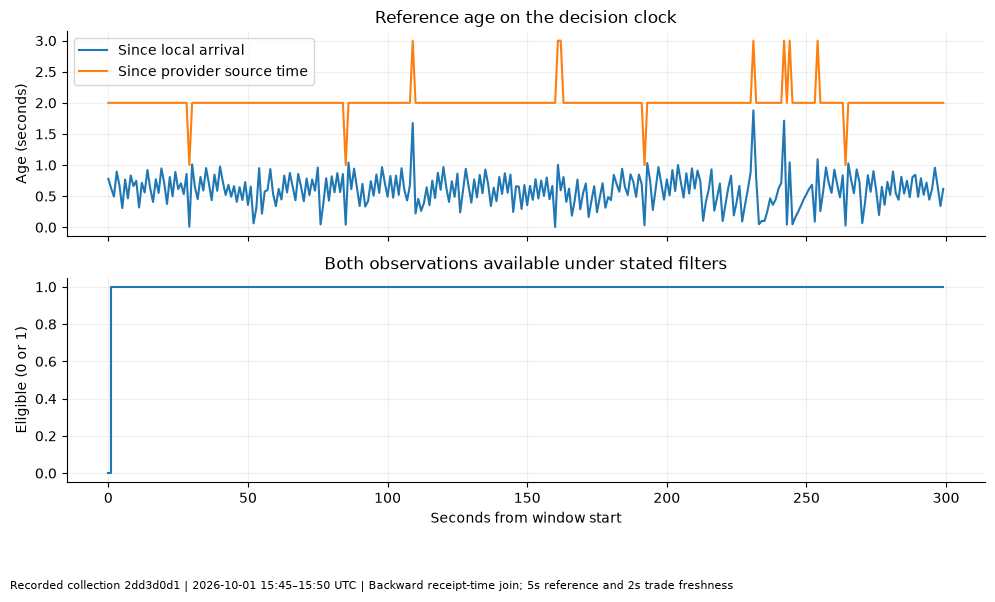

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
x = (aligned.time - pd.Timestamp(sample.start, tz="UTC")).dt.total_seconds()
axes[0].plot(x, aligned.reference_age_s, label="Since local arrival")
axes[0].plot(x, aligned.reference_source_age_s, label="Since provider source time")
axes[0].set(title="Reference age on the decision clock", ylabel="Age (seconds)")
axes[0].legend()
axes[1].step(x, aligned.both_eligible.astype(int), where="post")
axes[1].set(
    title="Both observations available under stated filters",
    xlabel="Seconds from window start",
    ylabel="Eligible (0 or 1)",
)
finish_plot(fig, sample, "Backward receipt-time join; 5s reference and 2s trade freshness")

## 
3. Compare an instantaneous trade with a smoothed proxy

We form a trailing mean of sixty one-second Binance last-trade samples. This is
only an approximate time average; it does not reproduce the reference vendor's
input prices, clock boundaries or BTC/USD currency. All sixty observations must
be present, so the first minute has no fabricated warm-up values.

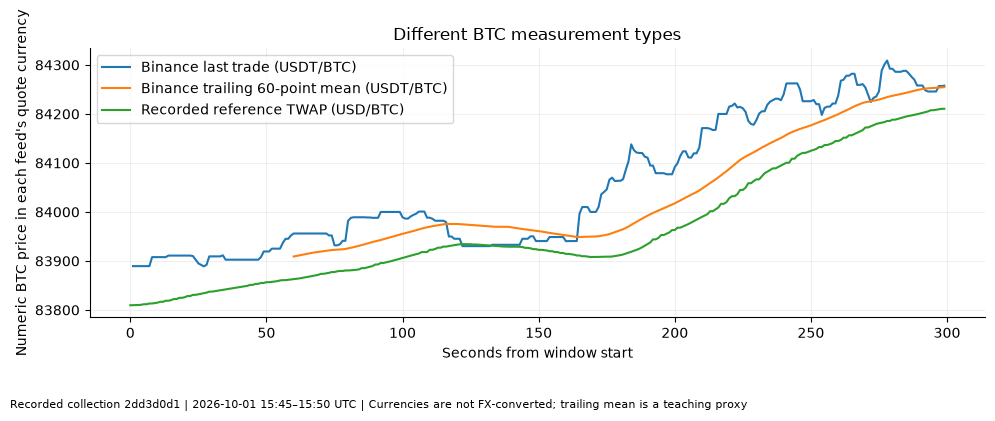

In [4]:
aligned["binance_60point_mean"] = btc.price_float.rolling(60, min_periods=60).mean().to_numpy()
fig, ax = plt.subplots()
ax.plot(x, aligned.binance_trade_price, label="Binance last trade (USDT/BTC)")
ax.plot(x, aligned.binance_60point_mean, label="Binance trailing 60-point mean (USDT/BTC)")
ax.plot(x, aligned.reference_value, label="Recorded reference TWAP (USD/BTC)")
ax.set(
    title="Different BTC measurement types",
    xlabel="Seconds from window start",
    ylabel="Numeric BTC price in each feed's quote currency",
)
ax.legend()
finish_plot(fig, sample, "Currencies are not FX-converted; trailing mean is a teaching proxy")

## 4. A numerical feed difference is not automatically an edge

The ratio below expresses the numerical difference in basis points. It mixes
currency, aggregation, source inputs and arrival timing. We deliberately do not
call it an exchange-arbitrage profit or a calibrated settlement basis estimate.
Those interpretations require matching price definitions and additional evidence.

,instant_difference_bps,smoothed_difference_bps
count,299.000000,240.000000
mean,10.435277,5.814393
std,5.877553,0.843758
min,-0.481544,4.353764
25%,6.641681,5.255250
50%,10.246875,5.812356
75%,14.377446,6.489893
max,26.082942,7.764864


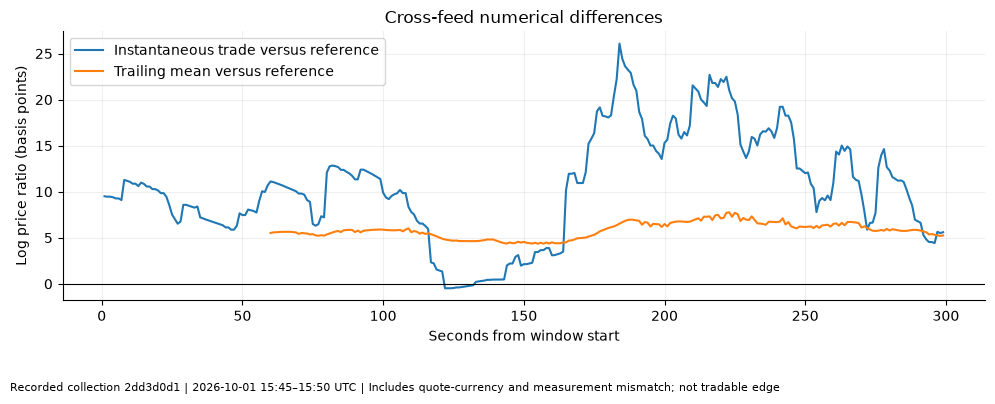

In [5]:
aligned["instant_difference_bps"] = (
    np.log(aligned.binance_trade_price / aligned.reference_value) * 10000
).where(aligned.both_eligible)
aligned["smoothed_difference_bps"] = (
    np.log(aligned.binance_60point_mean / aligned.reference_value) * 10000
).where(aligned.both_eligible)
display(aligned[["instant_difference_bps", "smoothed_difference_bps"]].describe())
fig, ax = plt.subplots()
ax.plot(x, aligned.instant_difference_bps, label="Instantaneous trade versus reference")
ax.plot(x, aligned.smoothed_difference_bps, label="Trailing mean versus reference")
ax.axhline(0, color="black", linewidth=0.8)
ax.set(
    title="Cross-feed numerical differences",
    xlabel="Seconds from window start",
    ylabel="Log price ratio (basis points)",
)
ax.legend()
finish_plot(fig, sample, "Includes quote-currency and measurement mismatch; not tradable edge")

## 5. Lead–lag as a diagnostic, not a causal trading claim

At lag +k, we correlate BTC's current sampled return with a reference change k
seconds later. Future values are allowed here **only as retrospective diagnostic
targets**, never as current features. A trailing average naturally reacts slowly;
its apparent lag is not proof that we can exploit a stale market quote.

,lag_s,correlation,paired_points
0,-10,-0.021200,289
1,-9,-0.056845,290
2,-8,0.038145,291
3,-7,-0.070571,292
4,-6,-0.000674,293
5,-5,-0.030105,294
6,-4,-0.036363,295
7,-3,-0.004385,296
8,-2,-0.045880,297
9,-1,-0.039556,298


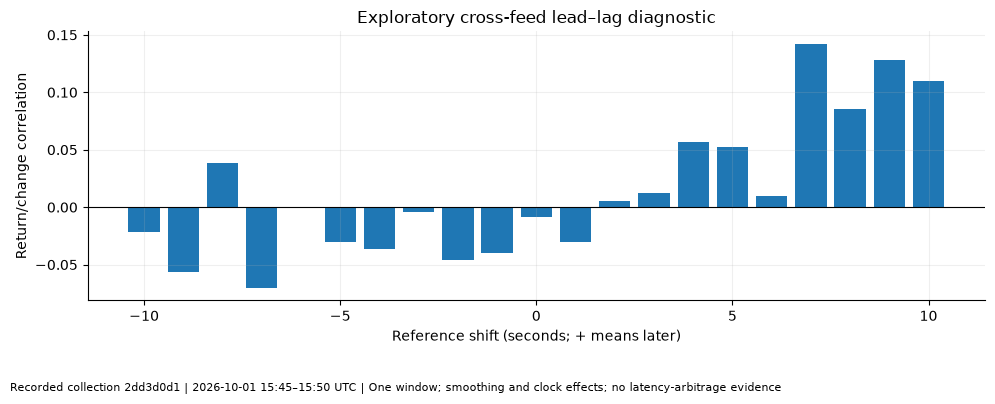

In [6]:
reference_change = np.log(aligned.reference_value).diff() * 10000
lag_report = pd.DataFrame(
    [
        {
            "lag_s": lag,
            "correlation": btc.log_return_bps.corr(reference_change.shift(-lag)),
            "paired_points": (
                btc.log_return_bps.notna() & reference_change.shift(-lag).notna()
            ).sum(),
        }
        for lag in range(-10, 11)
    ]
)
display(lag_report)
fig, ax = plt.subplots()
ax.bar(lag_report.lag_s, lag_report.correlation)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(
    title="Exploratory cross-feed lead–lag diagnostic",
    xlabel="Reference shift (seconds; + means later)",
    ylabel="Return/change correlation",
)
finish_plot(fig, sample, "One window; smoothing and clock effects; no latency-arbitrage evidence")

## Exercise — identify the hidden mismatch

If Binance jumps and the TWAP moves gradually, should a probability model treat
the entire difference as a reference-price error? Change the trailing mean to 30
or 90 points and explain what changes.

**Suggested answer:** part of the difference is expected from averaging. Changing
the mean changes its effective delay and warm-up. Currency and vendor differences
remain; aligning timestamps alone cannot remove them.

**Research use:** source freshness and well-defined feed differences may become
features after semantics are qualified. **Next:** [09 — Probability models](09_probability_models.ipynb).